# HappyWheel+ 접근성 분석 방법

휠체어 이용자 관점에서 유럽 9개 도시(런던, 파리, 루체른, 베른, 인터라켄, 밀라노, 베네치아, 피렌체, 로마)의 보행 네트워크에 접근성 점수를 매기고, 코스별로 "최단 경로"와 "접근성 경로"를 비교한 과정을 정리한 노트북입니다. 파이프라인 코드는 `pipeline/src/happywheel/`에 있고, 이 노트북은 그 결과물(`web/public/data/`)을 읽어 방법과 결과, 한계를 설명합니다.

구성: ① 문제와 데이터 출처 → ② 점수 공식 → ③ 도시별 결과 → ④ 사례 → ⑤ 현장 평가와 비교 → ⑥ 한계

## ① 문제와 데이터 출처

여행 코스를 짤 때 지도 앱의 최단 경로는 계단, 가파른 길, 울퉁불퉁한 노면을 구분하지 않습니다. 휠체어 이용자에게는 이 요소들이 경로 선택을 좌우합니다. 그래서 길 하나하나(구간, edge)에 접근성 점수를 매기고, 그 점수를 비용에 반영한 경로를 따로 구합니다.

| 자료 | 용도 | 출처 |
|---|---|---|
| 보행 네트워크 | 구간, 노면(`surface`, `smoothness`), 연석(`kerb`), 계단(`highway=steps`), `wheelchair` 태그 | OpenStreetMap (OSMnx, `network_type="walk"`), ODbL 1.0 |
| 편의시설 | 화장실, 엘리베이터, 벤치, 음수대 | OpenStreetMap |
| 고도 | 구간별 경사 계산 | Copernicus DEM GLO-30 (해상도 약 30 m) |
| 현장 평가 | 코스별 난이도, 별점, 메모 | 직접 다녀온 기록 (`config/cities.yaml`) |

분석 반경은 코스 정류장의 평균 좌표를 중심으로 `max(3000 m, 가장 먼 정류장 + 500 m)`입니다. 웹 배포용 파일 크기(도시당 gzip 2 MB) 때문에 런던, 파리, 밀라노는 반경을 줄였습니다. 분석 영역은 원이 아니라 중심에서 r 거리의 정사각형(한 변 2r)이고, 면적은 (2r)²입니다(OSMnx `graph_from_point`의 기본 bbox 방식).

In [1]:
import json
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.font_manager as fm
import numpy as np
import pandas as pd

from happywheel import scoring

DATA = Path("../../web/public/data")

# 한글 글꼴이 없는 환경에서도 실행은 되도록 한다(글자가 네모로 보일 수 있음)
installed = {f.name for f in fm.fontManager.ttflist}
for name in ["Malgun Gothic", "AppleGothic", "NanumGothic", "Noto Sans CJK KR"]:
    if name in installed:
        plt.rcParams["font.family"] = name
        break
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False

def read_json(path):
    return json.loads(Path(path).read_text(encoding="utf-8"))

meta = read_json(DATA / "cities.json")
cities = meta["cities"]
print("생성 시각:", meta["generated_at"])
print("기본 가중치:", meta["weights_default"], "/ alpha =", meta["alpha"])
pd.DataFrame(
    [{"도시": c["name_ko"], "반경(m)": c["radius_m"], "네트워크(km)": c["metrics"]["network_km"],
      "면적(km²)": c["metrics"]["area_km2"], "코스 수": c["course_count"]} for c in cities]
)

생성 시각: 2026-11-05T05:35:29+00:00
기본 가중치: {'slope': 1.0, 'surface': 0.8, 'kerb': 0.6, 'uncertainty': 0.3} / alpha = 3.0


,도시,반경(m),네트워크(km),면적(km²),코스 수
0,런던,2700.0,1120.17,29.16,2
1,파리,1800.0,557.60,12.96,2
2,루체른,3000.0,827.06,36.00,1
3,베른,3000.0,1054.43,36.00,1
4,인터라켄,3000.0,447.52,36.00,1
5,밀라노,2700.0,1334.20,29.16,2
6,베네치아,3000.0,201.20,36.00,2
7,피렌체,3000.0,954.64,36.00,2
8,로마,3000.0,1356.59,36.00,2


## ② 점수 공식

구간 점수는 감점 네 가지의 가중합을 100에서 뺀 값입니다(0~100으로 자름).

$$\text{score} = \mathrm{clip}\Big(100 - \sum_i w_i\, p_i,\ 0,\ 100\Big),\quad i \in \{\text{slope},\ \text{surface},\ \text{kerb},\ \text{uncertainty}\}$$

기본 가중치는 slope 1.0, surface 0.8, kerb 0.6, uncertainty 0.3입니다. `wheelchair=yes` 구간은 점수에 +10(최대 100)을 줍니다. `highway=steps`(단 `ramp=yes` 또는 `wheelchair=yes` 제외)와 `wheelchair=no`는 점수 대신 통과 불가(`blocked`)로 표시합니다. 항목별 감점값을 구간마다 따로 저장하기 때문에 웹에서 가중치를 바꿔도 다시 계산할 수 있습니다.

**경사 감점.** 최대 경사 5% 미만은 0, 5%에서 8.33%(ADA 경사로 기준 1:12)까지 0에서 50으로, 8.33%에서 12%까지 50에서 100으로 선형 증가하고 12% 이상은 100입니다. 구간 경사는 10 m 간격으로 고도를 뽑아 30 m 이상 창에서 계산한 최대값입니다.

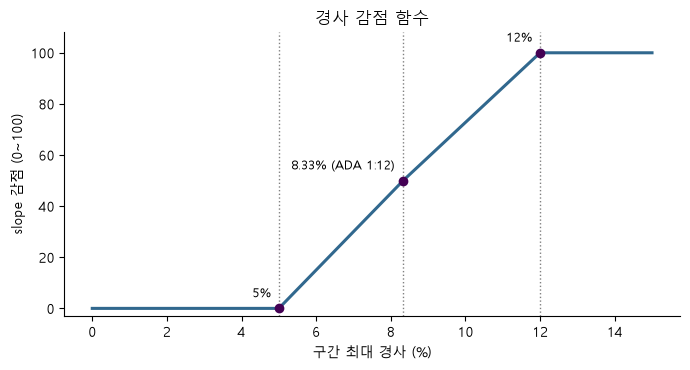

In [2]:
g = np.linspace(0, 15, 601)
p = [scoring.slope_penalty(x) for x in g]

fig, ax = plt.subplots(figsize=(7, 3.8))
ax.plot(g, p, color="#31688e", lw=2.2)
for x, label in [(5, "5%"), (8.33, "8.33% (ADA 1:12)"), (12, "12%")]:
    y = scoring.slope_penalty(x)
    ax.axvline(x, color="grey", ls=":", lw=1)
    ax.plot([x], [y], "o", color="#440154")
    ax.annotate(label, (x, y), textcoords="offset points", xytext=(-6, 8), ha="right", fontsize=9)
ax.set_xlabel("구간 최대 경사 (%)")
ax.set_ylabel("slope 감점 (0~100)")
ax.set_title("경사 감점 함수")
ax.set_ylim(-3, 108)
plt.tight_layout()
plt.show()

**노면 감점.** OSM `surface` 태그를 다섯 등급으로 묶고 등급별 기본 감점을 줍니다. 한 구간에 태그가 여러 개면 가장 나쁜 등급을 씁니다. `smoothness`가 bad 이하(bad, very_bad, horrible, very_horrible, impassable)이면 +20(최대 100)입니다. 태그가 없으면 노면 감점은 0이지만 아래 불확실성 감점이 붙습니다.

In [3]:
rows = []
for cls in ["smooth", "paving", "compacted", "cobble", "unpaved", "unknown"]:
    tags = sorted(t for t, c in scoring._SURFACE_TAG_CLASS.items() if c == cls)
    rows.append({
        "등급": cls,
        "기본 감점": scoring.surface_penalty(cls, None),
        "smoothness 나쁨(+20)": scoring.surface_penalty(cls, "bad"),
        "해당 surface 태그": ", ".join(tags) if tags else "(태그 없음 또는 목록 밖)",
    })
pd.DataFrame(rows).set_index("등급")

,기본 감점,smoothness 나쁨(+20),해당 surface 태그
등급,,,
smooth,0.0,20.0,"asphalt, concrete, concrete:plates, metal, pav..."
paving,20.0,40.0,"bricks, paving_stones"
compacted,40.0,60.0,"compacted, fine_gravel"
cobble,70.0,90.0,"cobblestone, sett, unhewn_cobblestone"
unpaved,90.0,100.0,"dirt, grass, gravel, ground, pebblestone, sand..."
unknown,0.0,20.0,(태그 없음 또는 목록 밖)


**연석과 불확실성.** 횡단 지점에 `kerb=raised`가 있으면 kerb 감점 60, `lowered`/`flush`/정보 없음은 0입니다. 연석 정보는 길 중간의 노드에 붙어 있으므로 네트워크를 단순화할 때 `kerb` 태그가 있는 노드는 남겨 둡니다. 노면 정보가 없으면 +15, 경사를 구할 수 없으면 +15를 uncertainty 감점으로 줍니다. 정보가 없다고 "좋은 길"로 취급하지 않기 위한 장치입니다.

**교량과 터널.** `bridge=yes`, `tunnel=yes` 구간은 지형 고도가 실제 노면과 다르므로 DEM 경사를 쓰지 않고, `incline` 태그가 있을 때만 그 값을 씁니다.

### 지형 보정: DSM의 경사 부풀림

Copernicus GLO-30은 지형(DTM)이 아니라 **표면 모델(DSM)**입니다. 건물과 나무 꼭대기 높이가 그대로 들어 있어서, 건물 가장자리를 지나는 길은 실제로 평평해도 30 m 안에 수 미터가 솟는 것처럼 계산될 수 있습니다. 이 때문에 보정 없이는 경사가 실제보다 크게 나옵니다.

그래서 타일을 읽은 뒤 회색조 열림(grey opening, 5 px 창)으로 창보다 좁은 돌출부를 깎고, 가우시안 평활(σ 1.5 px)로 계단 모양을 다듬은 다음, 최근접 대신 쌍선형 보간으로 표본을 뽑습니다. 아래는 루체른 네트워크에서 단계별로 측정한 값입니다. 세 행의 p90과 12% 초과 비율은 프로젝트 실행 중 기록한 값이고, **경사가 계산된 간선의 개수 기준**입니다. 마지막 열만 이 노트북이 최종 결과 파일에서 길이 가중으로 다시 계산합니다.

In [4]:
g = read_json(DATA / "lucerne" / "segments.geojson")
lu = pd.DataFrame([f["properties"] for f in g["features"]], columns=["len", "grade_max"]).dropna()
len_share = lu.loc[lu["grade_max"] > 12, "len"].sum() / lu["len"].sum()
count_share = (lu["grade_max"] > 12).mean()
del g

pd.DataFrame(
    [["원본 DSM, 최근접 표본", "20.0%", "22%", "—"],
     ["쌍선형 보간만 적용", "13.0%", "12%", "—"],
     ["열림 5 px + 가우시안 σ1.5 + 쌍선형 (최종)", "8.4%", "5.2%", f"{len_share:.1%}"]],
    columns=["방법", "최대 경사 p90 (간선 개수 기준)", "12% 초과 비율 (간선 개수 기준)", "12% 초과 비율 (길이 가중)"],
).set_index("방법")

,최대 경사 p90 (간선 개수 기준),12% 초과 비율 (간선 개수 기준),12% 초과 비율 (길이 가중)
방법,,,
"원본 DSM, 최근접 표본",20.0%,22%,—
쌍선형 보간만 적용,13.0%,12%,—
열림 5 px + 가우시안 σ1.5 + 쌍선형 (최종),8.4%,5.2%,14.7%


앞의 두 단계는 결과 파일을 남기지 않아 개수 기준 값만 있고, 길이 가중 값은 구할 수 없어 "—"로 두었습니다. 최종 결과를 다시 세면 개수 기준 12% 초과 비율이 5.2%로 표의 값과 맞습니다. 길이 가중 값(14.7%, 위 표)이 더 큰 것은 언덕과 산길의 간선이 평지 골목보다 길기 때문입니다. 루체른과 인터라켄은 반경 3 km 안에 산비탈 길이 들어 있어, 인터라켄은 길이 가중 12% 초과 비율이 약 40%에 이릅니다(아래 셀에서 확인).

In [5]:
g = read_json(DATA / "interlaken" / "segments.geojson")
it = pd.DataFrame([f["properties"] for f in g["features"]], columns=["len", "grade_max"]).dropna()
print(f"인터라켄 12% 초과 (길이 가중): {it.loc[it['grade_max'] > 12, 'len'].sum() / it['len'].sum():.1%}")
del g

인터라켄 12% 초과 (길이 가중): 39.9%


이는 근사입니다. 교량이나 폭 150 m(5 px)보다 큰 건물 단지는 완전히 제거되지 않을 수 있고, 반대로 실제 언덕 끝이 깎일 수도 있습니다. 전용 DTM을 대신하지는 못하므로 경사 점수는 이 한계를 감안해서 읽어야 합니다.

### 경로 비용

코스의 정류장을 순서대로 잇는 경로를 두 가지로 구합니다.

- 최단 경로: 비용 = 구간 길이. 막힌 구간도 지나갑니다(일반 보행자 기준).
- 접근성 경로: 비용 = 길이 × (1 + α × (100 − 점수) / 100), α = 3. 막힌 구간은 제외합니다.

정류장은 막힌 간선을 뺀 보행망에서 가장 큰 연결 덩어리의 가장 가까운 노드에 붙입니다. 이 거리가 150 m를 넘으면 `approximate`로 표시합니다.

## ③ 도시별 결과

구간 단위 값은 각 도시의 `segments.geojson`에서 필요한 속성(길이, 점수, 노면 등급, 최대 경사, blocked)만 읽어 길이 가중으로 요약합니다. 요약 지표는 `cities.json`의 값과 대조합니다.

In [6]:
seg_rows = []
for c in cities:
    gj = read_json(DATA / c["id"] / "segments.geojson")
    props = [f["properties"] for f in gj["features"]]
    df = pd.DataFrame(props, columns=["len", "score", "surface_class", "grade_max", "blocked"])
    blocked = df["blocked"].astype(bool)
    ok = df[~blocked]
    seg_rows.append({
        "id": c["id"], "name": c["name_ko"], "edges": len(df),
        "mean_score_len": np.average(ok["score"], weights=ok["len"]),
        "mean_score_json": c["metrics"]["mean_score"],
        "blocked_share": df.loc[blocked, "len"].sum() / df["len"].sum(),
    })
    del gj, props, df, ok
seg = pd.DataFrame(seg_rows).set_index("id")
seg.round(3)

,name,edges,mean_score_len,mean_score_json,blocked_share
id,,,,,
london,런던,52022,91.260,91.3,0.014
paris,파리,28159,87.232,87.2,0.016
lucerne,루체른,28573,68.666,68.7,0.022
bern,베른,32366,81.517,81.5,0.012
interlaken,인터라켄,6117,51.856,51.9,0.002
milan,밀라노,55460,92.803,92.8,0.009
venice,베네치아,10125,72.246,72.2,0.021
florence,피렌체,23870,81.714,81.7,0.005
rome,로마,45883,82.315,82.3,0.010


길이 가중 평균을 직접 계산한 값(`mean_score_len`)이 `cities.json`의 `mean_score`와 맞는지 확인하고, 이어서 도시를 평균 점수 순으로 놓고 비교합니다.

최대 차이: 0.05


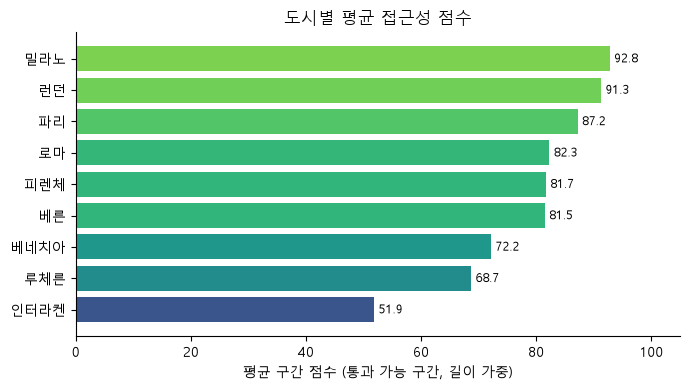

In [7]:
print("최대 차이:", round((seg["mean_score_len"] - seg["mean_score_json"]).abs().max(), 2))

order = sorted(cities, key=lambda c: c["metrics"]["mean_score"])
names = [c["name_ko"] for c in order]
vals = [c["metrics"]["mean_score"] for c in order]
colors = plt.cm.viridis(np.interp(vals, [40, 100], [0.1, 0.9]))

fig, ax = plt.subplots(figsize=(7, 4))
bars = ax.barh(names, vals, color=colors)
ax.bar_label(bars, fmt="%.1f", padding=3, fontsize=9)
ax.set_xlim(0, 105)
ax.set_xlabel("평균 구간 점수 (통과 가능 구간, 길이 가중)")
ax.set_title("도시별 평균 접근성 점수")
plt.tight_layout()
plt.show()

점수 차이는 도시의 지형과 OSM 태그 상태가 함께 만든 결과이고, 어느 쪽이 얼마나 기여했는지는 이 분석만으로 나눌 수 없습니다. 밀라노와 런던이 높고 인터라켄과 루체른이 낮습니다. 인터라켄과 루체른은 노면 태그가 없는 구간도 많아(아래 신뢰도 참조) 불확실성 감점의 영향을 함께 받습니다.

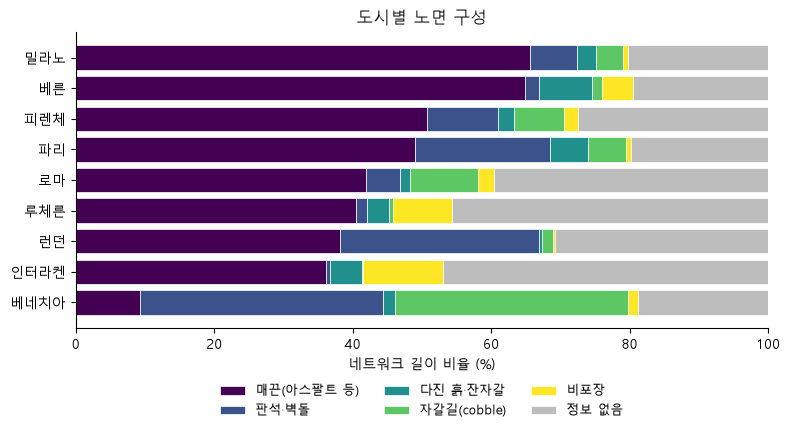

In [8]:
classes = ["smooth", "paving", "compacted", "cobble", "unpaved", "unknown"]
labels = ["매끈(아스팔트 등)", "판석·벽돌", "다진 흙·잔자갈", "자갈길(cobble)", "비포장", "정보 없음"]
palette = ["#440154", "#3b528b", "#21908d", "#5dc863", "#fde725", "#bdbdbd"]
order_s = sorted(cities, key=lambda c: c["metrics"]["surface_mix"]["smooth"])

fig, ax = plt.subplots(figsize=(8, 4.5))
left = np.zeros(len(order_s))
for cls, lab, col in zip(classes, labels, palette):
    v = np.array([c["metrics"]["surface_mix"][cls] for c in order_s]) * 100
    ax.barh([c["name_ko"] for c in order_s], v, left=left, color=col, label=lab, edgecolor="white", lw=0.5)
    left += v
ax.set_xlim(0, 100)
ax.set_xlabel("네트워크 길이 비율 (%)")
ax.set_title("도시별 노면 구성")
ax.legend(ncol=3, loc="upper center", bbox_to_anchor=(0.5, -0.15), frameon=False, fontsize=9)
plt.tight_layout()
plt.show()

회색(정보 없음)이 큰 도시는 노면 점수를 그대로 믿기 어렵습니다. 이 비율이 곧 아래 `surface_coverage`의 여집합입니다.

### 데이터 신뢰도

도시마다 OSM 태그가 얼마나 채워져 있는지가 다르므로, 점수와 함께 두 가지 신뢰도를 길이 기준으로 냅니다.

- `surface_coverage`: `surface` 태그로 노면 등급을 정할 수 있는 구간의 길이 비율
- `slope_coverage`: 고도로 경사를 계산할 수 있는 구간의 길이 비율

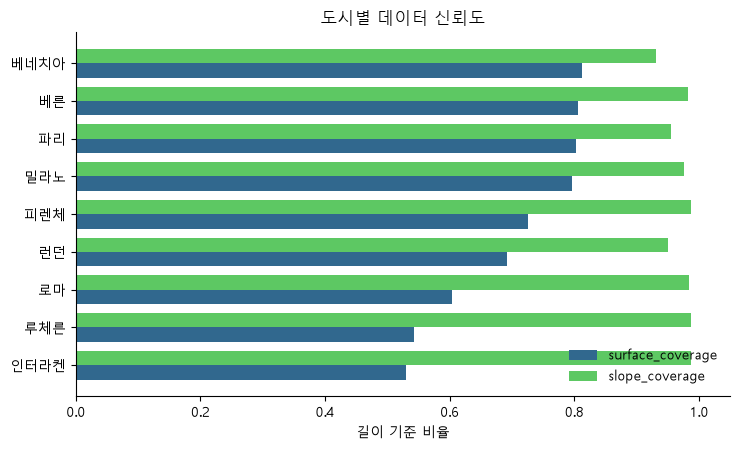

In [9]:
order_c = sorted(cities, key=lambda c: c["metrics"]["surface_coverage"])
y = np.arange(len(order_c))
h = 0.38
fig, ax = plt.subplots(figsize=(7.5, 4.6))
ax.barh(y - h/2, [c["metrics"]["surface_coverage"] for c in order_c], h, color="#31688e", label="surface_coverage")
ax.barh(y + h/2, [c["metrics"]["slope_coverage"] for c in order_c], h, color="#5dc863", label="slope_coverage")
ax.set_yticks(y, [c["name_ko"] for c in order_c])
ax.set_xlim(0, 1.05)
ax.set_xlabel("길이 기준 비율")
ax.set_title("도시별 데이터 신뢰도")
ax.legend(loc="lower right", frameon=False)
plt.tight_layout()
plt.show()

경사는 모든 도시에서 93% 이상 계산됩니다. 반면 노면 태그는 도시별 편차가 크고 인터라켄(약 53%)과 루체른(약 54%)이 가장 낮습니다. 두 도시의 점수는 노면에 대해 "모르는 구간"이 절반 가까이라는 전제 위에서 읽어야 합니다.

**연석 정보 커버리지.** `kerb=raised`가 있는 노드에 닿는 구간만 kerb 감점이 붙습니다. 실제 개수와 비율은 아래 표와 같습니다.

In [10]:
kerb_rows = []
for c in cities:
    gj = read_json(DATA / c["id"] / "segments.geojson")
    n = len(gj["features"])
    k = sum(1 for f in gj["features"] if f["properties"]["p_kerb"] > 0)
    kerb_rows.append({"도시": c["name_ko"], "구간 수": n, "kerb 감점 > 0 구간": k, "비율(%)": round(100 * k / n, 2)})
    del gj
pd.DataFrame(kerb_rows).set_index("도시")

,구간 수,kerb 감점 > 0 구간,비율(%)
도시,,,
런던,52022,271,0.52
파리,28159,227,0.81
루체른,28573,181,0.63
베른,32366,109,0.34
인터라켄,6117,0,0.00
밀라노,55460,2353,4.24
베네치아,10125,2,0.02
피렌체,23870,87,0.36
로마,45883,1520,3.31


## ④ 사례: 최단 경로 vs 접근성 경로

각 코스의 두 경로 지표는 `courses.json`의 `routes.shortest.metrics`, `routes.accessible.metrics`, `comparison`, `snap_max_m`, `approximate`에서 가져옵니다. 아래 표는 전체 15개 코스입니다.

In [11]:
rows = []
for c in cities:
    for co in read_json(DATA / c["id"] / "courses.json"):
        s, a = co["routes"]["shortest"]["metrics"], co["routes"]["accessible"]["metrics"]
        rows.append({
            "도시": c["name_ko"], "코스": co["name"],
            "최단 m": s["length_m"], "접근성 m": a["length_m"],
            "추가 m": co["comparison"]["extra_m"],
            "계단 최단→접근": f'{s["steps_count"]}→{a["steps_count"]}',
            "최대경사% 최단/접근": f'{s["max_grade_pct"]}/{a["max_grade_pct"]}',
            "자갈 m 최단/접근": f'{s["cobble_m"]}/{a["cobble_m"]}',
            "snap m": co["snap_max_m"], "근사": co["approximate"],
        })
cases = pd.DataFrame(rows)
cases

,도시,코스,최단 m,접근성 m,추가 m,계단 최단→접근,최대경사% 최단/접근,자갈 m 최단/접근,snap m,근사
0,런던,사우스뱅크 무계단 루프,3238.5,3481.0,242.5,10→0,7.5/7.2,8.5/91.2,118.4,False
1,런던,웨스트민스터–세인트 제임스–트라팔가,1555.0,1579.1,24.1,1→0,7.3/6.1,0.0/6.9,97.7,False
2,파리,루브르–뛸르리–오랑주리,1400.0,1764.9,364.9,1→0,3.4/3.5,161.8/161.5,40.4,False
3,파리,노트르담–시테섬–퐁네프,1134.2,1517.2,383.0,5→0,5.1/5.1,474.4/134.2,50.8,False
4,루체른,호반–카펠교–중앙역,948.6,1123.3,174.7,4→0,4.5/4.5,193.2/189.5,22.8,False
5,베른,아르강 전망–분수–연방의사당,722.6,745.6,23.0,0→0,3.9/3.9,191.7/33.6,25.3,False
6,인터라켄,회퍼브루케–호헤마트 공원,745.1,805.1,60.0,0→0,2.6/2.6,0.0/12.9,51.6,False
7,밀라노,두오모–갤러리아,489.5,516.9,27.4,0→0,4.9/4.5,0.0/0.0,50.7,False
8,밀라노,스포르체스코 성–브레라,823.0,874.8,51.8,0→0,4.8/2.2,164.7/0.0,53.6,False
9,베네치아,두칼레–산 마르코,176.5,232.5,56.0,0→0,7.5/4.9,155.0/65.6,24.4,False


세 사례를 봅니다. 수치는 모두 위 표(`courses.json`)에서 가져왔고, 아래 셀은 그 값을 다시 뽑아 보여줍니다.

In [12]:
for city, part in [("런던", "사우스뱅크"), ("베네치아", "리알토"), ("로마", "포로")]:
    r = cases[(cases["도시"] == city) & cases["코스"].str.contains(part)].iloc[0]
    print(f'{city} / {r["코스"]}')
    print(f'  최단 {r["최단 m"]} m, 접근성 {r["접근성 m"]} m (추가 {r["추가 m"]} m)')
    print(f'  계단 {r["계단 최단→접근"]}, 자갈 {r["자갈 m 최단/접근"]} m, snap {r["snap m"]} m, 근사={r["근사"]}')

런던 / 사우스뱅크 무계단 루프
  최단 3238.5 m, 접근성 3481.0 m (추가 242.5 m)
  계단 10→0, 자갈 8.5/91.2 m, snap 118.4 m, 근사=False
베네치아 / 리알토–산 폴로
  최단 355.2 m, 접근성 624.6 m (추가 269.4 m)
  계단 5→0, 자갈 127.5/72.5 m, snap 325.2 m, 근사=True
로마 / 포로 로마노 주변 산책
  최단 874.0 m, 접근성 1039.4 m (추가 165.4 m)
  계단 1→0, 자갈 784.6/401.9 m, snap 16.7 m, 근사=False


**런던 사우스뱅크 무계단 루프.** 최단 경로는 통과 불가로 분류된 계단 10곳을 지나고, 접근성 경로는 0곳입니다. 우회 거리는 242.5 m(최단 경로의 약 7.5%)입니다. 대신 접근성 경로의 자갈길(cobble)이 8.5 m에서 91.2 m로 늘었습니다. 계단을 피하는 대가로 노면이 거친 구간을 일부 받아들이는 선택이 경로 비용 안에서 일어난 것입니다.

**베네치아 리알토–산 폴로.** 최단 경로는 계단 5곳을 지나고 접근성 경로는 0곳이지만, 거리는 355.2 m에서 624.6 m로 늘어납니다. 이 결과는 **근사**로만 읽어야 합니다. 정류장이 접근 가능한 보행망에서 최대 325.2 m 떨어진 곳에 붙었기 때문입니다(`approximate=true`). 베네치아는 운하를 건너는 다리가 대부분 계단이어서, 계단을 뺀 접근 가능 보행망이 여러 조각으로 쪼개집니다. 정류장 가까이에 가장 큰 덩어리의 노드가 없으면 멀리 붙일 수밖에 없고, 그만큼 경로가 정류장 실제 위치에서의 경로와 달라집니다. 같은 도시의 두칼레–산 마르코 코스(snap 24.4 m)와는 신뢰 수준이 다릅니다.

**로마 포로 로마노 주변 산책.** 최단 경로의 자갈길이 784.6 m이고 접근성 경로는 401.9 m로 줄지만, 접근성 경로 길이(1039.4 m)의 40% 가까이가 여전히 자갈길입니다. 최대 경사도 두 경로 모두 12.0%입니다. 대체 경로가 없는 구간은 경로를 바꿔도 피할 수 없다는 것을 보여주는 사례입니다. 접근성 경로가 모든 코스에서 극적으로 다르지는 않습니다(위 표에서 계단과 자갈이 거의 같은 코스도 있습니다).

## ⑤ 현장 평가와 비교

`courses.json`의 `field`에는 직접 걸어보고 적은 휠체어 난이도(1~5)가 있습니다. 15개 코스 중 기록이 있는 10개 코스를 계산된 접근성 경로의 평균 점수(`routes.accessible.metrics.mean_score`)와 나란히 놓았습니다. 난이도는 높을수록 어렵고, 점수는 높을수록 쉬운 방향입니다.

In [13]:
rows = []
for c in cities:
    for co in read_json(DATA / c["id"] / "courses.json"):
        if co["field"] is None:
            continue
        rows.append({
            "도시": c["name_ko"], "코스": co["name"],
            "현장 난이도(1~5)": co["field"]["difficulty"],
            "계산 점수(접근성 경로)": co["routes"]["accessible"]["metrics"]["mean_score"],
        })
field = pd.DataFrame(rows).sort_values("현장 난이도(1~5)").reset_index(drop=True)
print("현장 기록이 있는 코스:", len(field))
field

현장 기록이 있는 코스: 10


,도시,코스,현장 난이도(1~5),계산 점수(접근성 경로)
0,베른,아르강 전망–분수–연방의사당,1,96.0
1,루체른,호반–카펠교–중앙역,1,88.9
2,런던,웨스트민스터–세인트 제임스–트라팔가,2,94.0
3,파리,노트르담–시테섬–퐁네프,2,89.3
4,피렌체,우피치–베키오 다리–피티궁,2,75.3
5,밀라노,두오모–갤러리아,3,91.4
6,베네치아,두칼레–산 마르코,3,72.7
7,런던,사우스뱅크 무계단 루프,3,90.0
8,파리,루브르–뛸르리–오랑주리,4,85.8
9,로마,포로 로마노 주변 산책,5,71.4


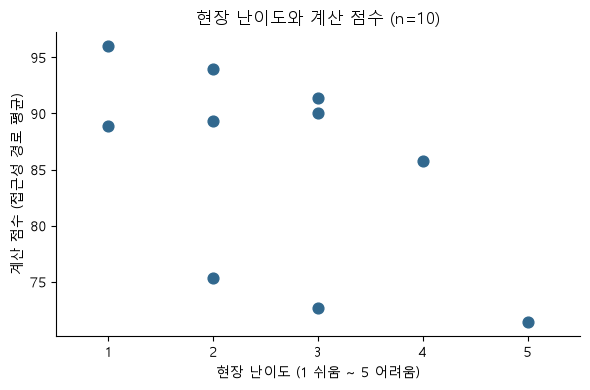

In [14]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(field["현장 난이도(1~5)"], field["계산 점수(접근성 경로)"], s=60, color="#31688e")
ax.set_xticks([1, 2, 3, 4, 5])
ax.set_xlim(0.5, 5.5)
ax.set_xlabel("현장 난이도 (1 쉬움 ~ 5 어려움)")
ax.set_ylabel("계산 점수 (접근성 경로 평균)")
ax.set_title("현장 난이도와 계산 점수 (n=10)")
plt.tight_layout()
plt.show()

표본이 10개 코스뿐이고, 난이도는 한 사람이 한 번 다녀온 주관적 기록이며, 코스 길이와 방문 시점(혼잡도)도 제각각입니다. 계산 점수는 구간 속성의 평균이어서 붐비는 관광지의 혼잡, 일시적 공사, 보도 폭 같은 현장 요인을 담지 못합니다. **n=10이므로 상관계수나 검정 같은 통계적 결론은 내리지 않습니다.** 이 표는 계산 점수가 현장 인상과 크게 어긋나는 코스가 있는지 눈으로 점검하고, 어긋나는 이유를 찾는 출발점으로만 씁니다.

## ⑥ 한계

- **OSM 태그 누락.** `surface`를 알 수 없는 구간이 도시에 따라 약 19~47%입니다. 이 구간은 노면 감점 0에 불확실성 +15가 붙을 뿐이라 실제로는 거친 길일 수 있습니다. `kerb`, `wheelchair`, `incline`은 더 드물게 기록됩니다. 연석은 `kerb=raised`가 붙은 구간(kerb 감점 > 0)이 도시 전체 구간의 0~4% 수준입니다(위 셀의 측정값, 인터라켄은 원본 OSM에 `raised`가 없어 0). 점수는 "지도에 적힌 만큼의 접근성"입니다.
- **DEM 해상도와 표면 모델.** 30 m 격자는 짧은 급경사(경사로, 연석 단차)를 평균 속으로 지웁니다. DSM 보정은 근사여서 교량이나 큰 건물 단지 주변의 경사는 틀릴 수 있습니다. 교량과 터널 구간은 DEM을 쓰지 않아 `incline` 태그가 없으면 경사 정보 없음입니다.
- **보도 폭, 횡단 신호, 혼잡, 공사.** 모델에 들어 있지 않습니다.
- **실내와 대중교통 미포함.** 건물 내부 이동, 지하철·버스·트램의 휠체어 접근성은 다루지 않습니다. 엘리베이터와 화장실은 위치 정보로만 표시합니다.
- **정류장 연결.** 정류장은 접근 가능한 가장 큰 연결 덩어리에 붙이기 때문에, 덩어리에서 먼 정류장(베네치아 사례)은 경로가 근사입니다. 현재 `approximate` 코스는 한 개입니다.
- **가중치와 α.** 감점 값과 기본 가중치는 ADA 경사 기준을 제외하면 경험적으로 정한 값이고, 현장 데이터로 보정하지 않았습니다. 웹에서 가중치를 바꿔볼 수 있는 것도 이 때문입니다.
- **현장 검증 부족.** ⑤에서 보았듯 현장 기록은 10개 코스, 한 사람의 평가입니다.

데이터: © OpenStreetMap contributors (ODbL 1.0). Copernicus DEM GLO-30 © DLR e.V. 2010-2014 and © Airbus Defence and Space GmbH 2014-2018 provided under COPERNICUS by the European Union and ESA; all rights reserved.